# EV Customer Prioritization
## 02. Modeling and prioritization

**Nu Quynh Chau Nguyen | MSBA265 | Fall 2026**

**Business question:** Which customers should an EV dealership prioritize for contact when its outreach capacity is limited?

This notebook compares three classifiers, chooses one using validation data,
and evaluates the selected model on a separate holdout. It saves the exact
final preprocessing-and-model pipeline used by the Streamlit application.
The application's job is to rank a batch of customer profiles, not to make a
guaranteed purchase or revenue forecast.

**Reading order:** problem and data → fixed splits → candidate models →
validation comparison → model selection → holdout evaluation → saved model
and app handoff. Run all cells in order to reproduce the results.

### 1. What the data can and cannot tell us

The source is the professor-approved Kaggle competition
[Predicting Electric Vehicle Purchases](https://www.kaggle.com/competitions/playground-series-s6e9).
The training file contains **668,665 synthetic profiles**, with **13 candidate
predictors**, an `id`, and the supplied `Will_Buy_EV` target. The separate
Kaggle `test.csv` has **286,571 unlabeled profiles**; it is not our labeled
internal holdout and cannot establish model accuracy.

We map **No to 0** and **Yes to 1**. The target is a supplied dataset label; it is not documented as a verified
transaction or a purchase within a known time window.
Scores in this project estimate the Yes-label probability in this synthetic
dataset. Results do not establish that contacting a person causes a purchase.

Initial EDA already inspected the full labeled dataset. The new split is
frozen before model fitting and selection, but this holdout is **not a dataset
nobody has ever looked at**. We will not repeatedly tune models against its
results. A genuinely external labeled dataset would be a stronger future test.

In [1]:
from pathlib import Path
import importlib.metadata
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

# Support either the project root or notebooks/ as the current directory.
locations = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in locations if (p / "ev_project").is_dir() and (p / "train.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete project folder containing train.csv and ev_project/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from ev_project.modeling import (
    load_training_data, make_splits, split_summary, make_candidates,
    fit_candidates, evaluate_candidates, select_model, fit_final_model,
    evaluate_final, save_training_artifacts,
)

SEED = 42
FIGURES = ROOT / "docs" / "reports" / "modeling" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Dummy baseline": "#87949A", "Logistic Regression": "#187A89", "Decision Tree": "#BC643A"}

def show_table(frame):
    display(frame.reset_index(drop=True))

environment = pd.DataFrame({
    "Package": ["Python", "pandas", "numpy", "scikit-learn", "joblib", "streamlit"],
    "Version": [sys.version.split()[0], *[importlib.metadata.version(p) for p in ["pandas", "numpy", "scikit-learn", "joblib", "streamlit"]]],
})
show_table(environment)

,Package,Version
0,Python,3.13.9
1,pandas,2.2.3
2,numpy,2.3.5
3,scikit-learn,1.9.1
4,joblib,1.6.0
5,streamlit,1.65.0


### 2. Modeling inputs

`id` identifies a row; it is never a predictor. The target is never included
among the input features. We keep all rows and the conservative cleaning
decisions documented in Notebook 01.

The stored EDA data have seven numeric and six categorical fields. For
modeling, we treat `Environmental_Concern_Level` as **categorical**, making
**six numeric and seven categorical inputs**. Its values are codes 1–5;
survey wording, category anchors, and an equal-interval interpretation are
unknown. We do not label them as “low” or “high” concern.

In [2]:
training_data = load_training_data(ROOT)
FEATURES = [column for column in training_data.columns if column not in ["id", "Will_Buy_EV"]]
assert len(FEATURES) == 13
assert set(training_data["Will_Buy_EV"].unique()) == {0, 1}
target_summary = training_data["Will_Buy_EV"].value_counts().sort_index()
show_table(pd.DataFrame({
    "Label": ["No (0)", "Yes (1)"],
    "Profiles": [int(target_summary.loc[0]), int(target_summary.loc[1])],
    "Share": [target_summary.loc[0] / len(training_data), target_summary.loc[1] / len(training_data)],
}))
print(f"Input shape: {training_data.shape[0]:,} rows; {len(FEATURES)} predictors; ID and target excluded from X.")

,Label,Profiles,Share
0,No (0),551886,0.825355
1,Yes (1),116779,0.174645


Input shape: 668,665 rows; 13 predictors; ID and target excluded from X.


In [3]:
input_dictionary = pd.DataFrame([
    ("Demographics and area", "Age", "Numeric", "Age in years"),
    ("Demographics and area", "Gender", "Categorical", "Supplied gender category"),
    ("Demographics and area", "City_Type", "Categorical", "Urban, Suburban, or Rural"),
    ("Finance", "Annual_Income_USD", "Numeric", "Annual income in USD"),
    ("Finance", "Subsidy_Available", "Categorical", "Supplied subsidy-availability category"),
    ("Transportation", "Daily_Commute_km", "Numeric", "Daily commute distance in km"),
    ("Transportation", "Number_of_Cars_Owned", "Numeric", "Number of cars owned"),
    ("Transportation", "Current_Car_Type", "Categorical", "Supplied vehicle-type category"),
    ("Charging", "Charging_Stations_Near_Home", "Numeric", "Nearby station count; radius unspecified"),
    ("Charging", "Charging_Stations_Near_Work", "Numeric", "Nearby station count; radius unspecified"),
    ("Charging", "Home_Charging_Possible", "Categorical", "Supplied home-charging possibility"),
    ("Attitudes", "Environmental_Concern_Level", "Categorical", "Codes 1–5; category anchors unknown"),
    ("Attitudes", "Range_Anxiety_Level", "Categorical", "Low, Medium, or High supplied category"),
], columns=["Group", "Input", "Model treatment", "Meaning / limitation"])
show_table(input_dictionary)

,Group,Input,Model treatment,Meaning / limitation
0,Demographics and area,Age,Numeric,Age in years
1,Demographics and area,Gender,Categorical,Supplied gender category
2,Demographics and area,City_Type,Categorical,"Urban, Suburban, or Rural"
3,Finance,Annual_Income_USD,Numeric,Annual income in USD
4,Finance,Subsidy_Available,Categorical,Supplied subsidy-availability category
5,Transportation,Daily_Commute_km,Numeric,Daily commute distance in km
6,Transportation,Number_of_Cars_Owned,Numeric,Number of cars owned
7,Transportation,Current_Car_Type,Categorical,Supplied vehicle-type category
8,Charging,Charging_Stations_Near_Home,Numeric,Nearby station count; radius unspecified
9,Charging,Charging_Stations_Near_Work,Numeric,Nearby station count; radius unspecified


### 3. Freeze training, validation, and holdout groups

We use a **stratified 70% / 15% / 15% split** with random seed **42**, so each
group keeps a similar Yes-label share. Integer rounding determines the exact
row counts. A saved ID-to-split manifest records membership for inspection.

- **Training:** learn preprocessing and candidate model parameters.
- **Validation:** compare models and select one using the rule stated below.
- **Holdout:** evaluate the selected final model after refitting on training
  plus validation. Do not use this result to choose a different model.

Each group's IDs are disjoint. Stratification uses the labels to balance
group composition; the holdout labels do not enter preprocessing or fitting.

In [4]:
splits = make_splits(training_data, seed=SEED)
split_table = split_summary(splits)
show_table(split_table)
train_ids, validation_ids, holdout_ids = [set(splits[name]["id"]) for name in ["train", "validation", "holdout"]]
assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(holdout_ids)
assert validation_ids.isdisjoint(holdout_ids)
assert sum(len(part) for part in splits.values()) == len(training_data)
print("Verified disjoint IDs and complete row coverage.")

,split,records,fraction,yes_count,yes_rate
0,train,468065,0.699999,81745,0.174645
1,validation,100300,0.150000,17517,0.174646
2,holdout,100300,0.150000,17517,0.174646


Verified disjoint IDs and complete row coverage.


### 4. Compare three candidates with train-only preprocessing

| Candidate | Purpose | Fixed configuration |
|---|---|---|
| Dummy baseline | Ignore predictors and use training-label prevalence | `DummyClassifier(strategy="prior")` |
| Logistic Regression | Transparent multivariable probability baseline | `C=1`, `solver="lbfgs"`, `max_iter=1000` |
| Decision Tree | Capture limited nonlinear relationships and interactions | `max_depth=6`, `min_samples_leaf=200`, `random_state=42` |

A scikit-learn `Pipeline` carries preprocessing and the classifier together.
Categorical inputs use one-hot encoding. Numeric inputs are standardized for
Logistic Regression; a tree does not require this scaling. All learned
transformations fit **only on training rows** during candidate comparison.
We do not apply SMOTE or class weighting in these initial probability
baselines. These are fixed, modest configurations, not an extensive search.

The encoder handles an unseen category without a runtime error during model
evaluation. The application applies stricter schema validation and rejects
unsupported input categories rather than quietly treating them as known.

### 4.1 How Logistic Regression learns and why these settings were chosen

The fitted pipeline turns each synthetic customer profile into numeric inputs.
One-hot encoding represents categories without inventing numeric distances;
standardization puts the six numeric predictors on comparable scales. During
candidate comparison, both transformations learn from training rows only.

For a profile with transformed features x, Logistic Regression computes a score
z = wᵀx + b and converts it to a Yes-label probability using the logistic function.
Training adjusts w and b to reduce binary log loss while applying L2 regularization.
With no class or sample weights in this experiment, the minimized objective is
mean binary log loss plus the L2 penalty ||w||² / (2 × C × n), where n is the
number of training rows.

The intercept is excluded from the penalty. The stable implementation handles
large scores without directly exponentiating them. The diagnostic figure below
reports the **mean prediction log loss without the regularization term**, so the
training and validation curves have the same interpretation. This loss evaluates
probability estimates; the project's business selection metric remains Lift@K.

L-BFGS uses loss values, gradients, and an approximation to curvature to update
the coefficients. It is a reasonable initial solver for this structured,
moderate-dimensional problem. The existing model has already completed a fit;
this does not establish that its solver or settings are optimal.

| Choice | Role and reason for the initial setting |
|---|---|
| C = 1 | A transparent initial L2 regularization setting. Smaller C strengthens shrinkage; this value was fixed before comparison, not selected by a tuning search. |
| solver = lbfgs | Uses gradient and curvature information for a smooth logistic objective. Numeric scaling supports stable optimization. |
| max_iter = 1000 | A generous upper iteration cap, allowing the stopping criterion to finish earlier. It is not a target number of updates. |
| tol = 0.0001 | The estimator's configured stopping tolerance. Exact optimizer termination details are not exposed by the public estimator interface. |
| Tree max_depth = 6 | Limits the complexity of interactions and helps keep the comparison tree understandable. It is not a proven best depth. |
| Tree min_samples_leaf = 200 | Requires substantial support for a terminal group and discourages small, unstable leaves in this large dataset. It is an initial design choice. |
| Dummy strategy = prior | Establishes a label-prevalence benchmark without learning profile-specific differences. |

These are three prespecified baselines. A future tuning study would use training
and validation, or cross-validation within development data; the existing holdout
would not be reused to search for better settings.

**Iterations and fit checks.** The actual number of optimizer iterations is
available after fitting; the cap alone does not tell us how many were used.
Dummy and Decision Tree fits have no corresponding L-BFGS iteration count.
The fit wrapper treats a convergence warning as a failed fit and records elapsed
time, row count, parameters, and actual iterations for new fits. Completion
without that warning is recorded directly; a count below the cap does not reveal
which exact internal stopping criterion fired.

Sources: [Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
[Decision Tree](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html),
and [native fit callbacks](https://scikit-learn.org/stable/modules/generated/sklearn.callback.FitCallback.html).


In [5]:
candidates = make_candidates()
for name, pipeline in candidates.items():
    print(f"\n{name}")
    print(pipeline)
candidates = fit_candidates(candidates, splits["train"])
print("All candidate pipelines fitted using training rows only.")


Dummy baseline
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('numeric', 'passthrough',
                                                  ['Age', 'Annual_Income_USD',
                                                   'Daily_Commute_km',
                                                   'Number_of_Cars_Owned',
                                                   'Charging_Stations_Near_Home',
                                                   'Charging_Stations_Near_Work']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Environmental_Concern_Level',
                                                   'Gender', 'City_Type',
                                                   'Current_Car_Type',
                                             

Completed Dummy baseline in 0.4 seconds.


Fitting Logistic Regression on 468,065 training records...


Completed Logistic Regression in 0.9 seconds.


Fitting Decision Tree on 468,065 training records...


Completed Decision Tree in 1.2 seconds.


All candidate pipelines fitted using training rows only.


### 5. Define K and the model-selection rule before reading results

**K** is contact capacity: the number of customer profiles the dealership can
contact. We compare **1%, 5%, 10%, and 20%** of the evaluation batch, rounded
up to a whole profile and capped at its size. The app lets the user choose an
actual count instead of a percentage.

| Metric | Interpretation |
|---|---|
| Precision@K | Yes-labeled profiles in the top K divided by K |
| Recall@K | Yes-labeled profiles in the top K divided by all Yes labels in the evaluation group |
| Lift@K | Precision@K divided by that evaluation group's Yes-label share |
| ROC-AUC | Overall separation of Yes and No scores across thresholds |
| Average precision | Precision-recall summary; useful with an imbalanced target |
| Brier score | Mean squared probability error; lower is better |

Our primary selection rule is **highest validation Lift@10%**, followed by
ROC-AUC if lift ties. A fixed simplicity order resolves any remaining tie:
Dummy baseline, then Logistic Regression, then Decision Tree. At a fixed K and prevalence, comparing lift is equivalent to comparing
precision. The 10% choice is a transparent working capacity assumption; a
dealership's real capacity would need confirmation.

The Dummy model emits a constant probability. Tied scores use a fixed,
label-independent SHA-256 ordering of seed 42 and ID. This also makes tied
tree scores reproducible. We show both realized Dummy results and the
**expected random-selection baseline: precision = prevalence and lift = 1**.
Random expectation is not a claim that every realized shortlist has lift 1.

In [6]:
validation_metrics, validation_ranking, validation_predictions = evaluate_candidates(candidates, splits["validation"])
comparison_columns = ["model", "n", "yes_rate", "roc_auc", "average_precision", "brier_score", "primary_k", "precision_at_k", "recall_at_k", "lift_at_k"]
show_table(validation_metrics[comparison_columns].sort_values(["lift_at_k", "roc_auc", "model"], ascending=[False, False, True]))
show_table(validation_ranking)

,model,n,yes_rate,roc_auc,average_precision,brier_score,primary_k,precision_at_k,recall_at_k,lift_at_k
0,Logistic Regression,100300,0.174646,0.938228,0.741027,0.073471,10030,0.791027,0.452931,4.529314
1,Decision Tree,100300,0.174646,0.936659,0.722748,0.073472,10030,0.787637,0.450990,4.509905
2,Dummy baseline,100300,0.174646,0.500000,0.174646,0.144145,10030,0.176869,0.101273,1.012730


,model,split,contact_fraction,k,precision_at_k,recall_at_k,lift_at_k,expected_random_precision,expected_random_lift
0,Dummy baseline,validation,0.01,1003,0.189432,0.010847,1.084661,0.174646,1.0
1,Dummy baseline,validation,0.05,5015,0.174078,0.049837,0.996746,0.174646,1.0
2,Dummy baseline,validation,0.10,10030,0.176869,0.101273,1.012730,0.174646,1.0
3,Dummy baseline,validation,0.20,20060,0.175474,0.200948,1.004738,0.174646,1.0
4,Logistic Regression,validation,0.01,1003,0.897308,0.051379,5.137866,0.174646,1.0
5,Logistic Regression,validation,0.05,5015,0.844865,0.241879,4.837586,0.174646,1.0
6,Logistic Regression,validation,0.10,10030,0.791027,0.452931,4.529314,0.174646,1.0
7,Logistic Regression,validation,0.20,20060,0.659671,0.755438,3.777188,0.174646,1.0
8,Decision Tree,validation,0.01,1003,0.866401,0.049609,4.960895,0.174646,1.0
9,Decision Tree,validation,0.05,5015,0.845862,0.242165,4.843295,0.174646,1.0


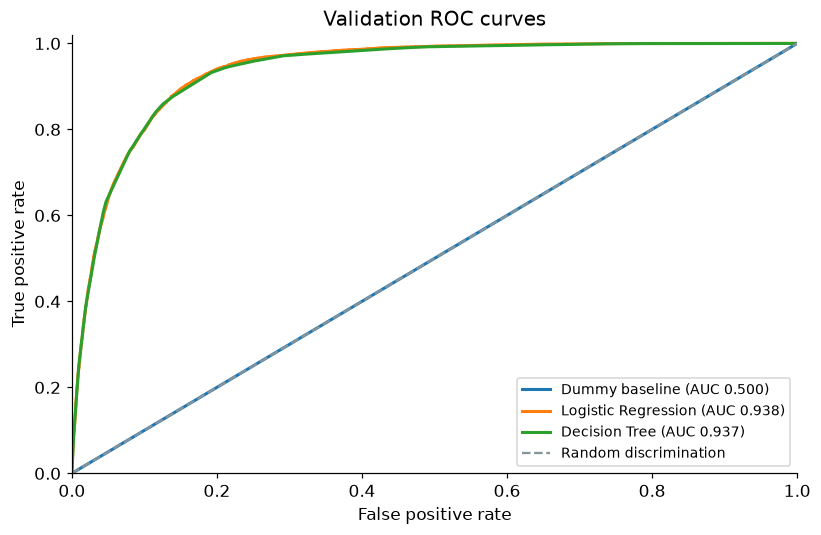

In [7]:
fig, ax = plt.subplots(figsize=(7.6, 5.0))
for name in candidates:
    predictions = validation_predictions.loc[validation_predictions["model"] == name]
    fpr, tpr, _ = roc_curve(predictions["y_true"], predictions["yes_probability"])
    auc_value = roc_auc_score(predictions["y_true"], predictions["yes_probability"])
    ax.plot(fpr, tpr, label=f"{name} (AUC {auc_value:.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], color="#87949A", linestyle="--", label="Random discrimination")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Validation ROC curves", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "validation_roc.png", bbox_inches="tight")
plt.show()

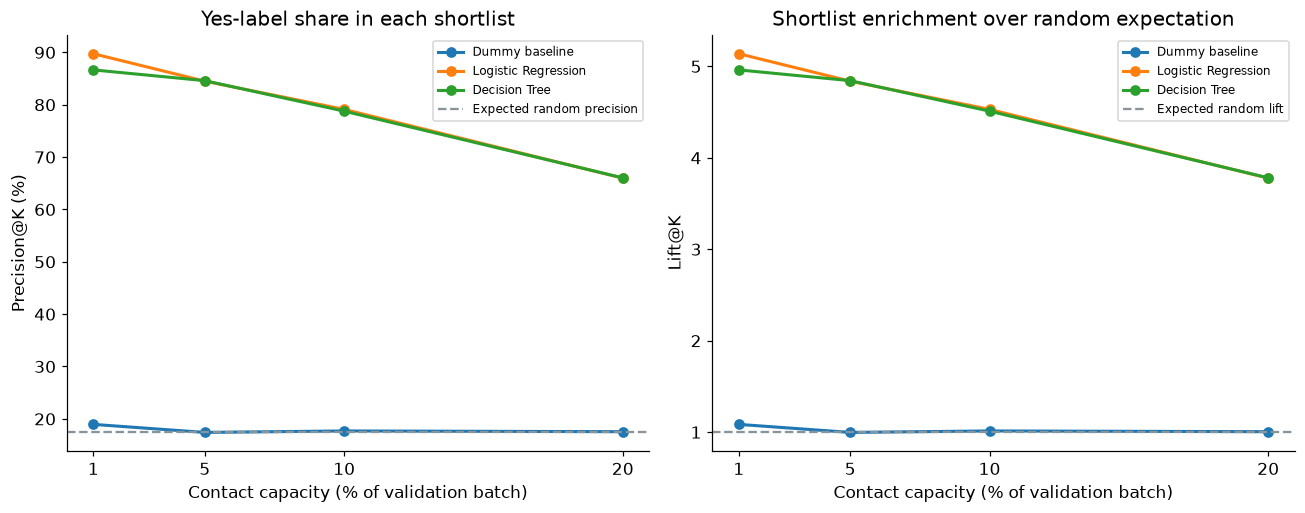

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name in candidates:
    rows = validation_ranking.loc[validation_ranking["model"] == name].sort_values("contact_fraction")
    capacity_percent = 100 * rows["contact_fraction"]
    axes[0].plot(capacity_percent, 100 * rows["precision_at_k"], marker="o", linewidth=2, label=name)
    axes[1].plot(capacity_percent, rows["lift_at_k"], marker="o", linewidth=2, label=name)
prevalence = splits["validation"]["Will_Buy_EV"].mean()
axes[0].axhline(100 * prevalence, color="#87949A", linestyle="--", label="Expected random precision")
axes[1].axhline(1, color="#87949A", linestyle="--", label="Expected random lift")
axes[0].set(xlabel="Contact capacity (% of validation batch)", ylabel="Precision@K (%)", title="Yes-label share in each shortlist")
axes[1].set(xlabel="Contact capacity (% of validation batch)", ylabel="Lift@K", title="Shortlist enrichment over random expectation")
for ax in axes:
    ax.set_xticks([1, 5, 10, 20])
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "validation_contact_capacity.png", bbox_inches="tight")
plt.show()

### 6. Select once, then refit on 85% of the labeled data

The selection function reads validation metrics only. The holdout has not
influenced candidate fitting or model choice. We now refit a fresh copy of
the chosen pipeline on training plus validation, allowing its preprocessing
and classifier to learn from 85% of the labeled rows.

Validation results describe the earlier 70%-fit candidates. The following
holdout results describe the **refitted 85%-fit final pipeline**. They are
different evaluations; we do not label one as the other.

In [9]:
selected_model = select_model(validation_metrics)
selected_validation = validation_metrics.loc[validation_metrics["model"] == selected_model].iloc[0]
display(Markdown(
    f"**Selected model: {selected_model}.** Its validation Lift@10% is "
    f"**{selected_validation['lift_at_k']:.3f}**, with ROC-AUC **{selected_validation['roc_auc']:.3f}**. "
    "Selection follows the stated validation rule; it does not use holdout results."
))
final_pipeline = fit_final_model(candidates[selected_model], splits)
print(f"Final pipeline refitted on {len(splits['train']) + len(splits['validation']):,} training-plus-validation rows.")

**Selected model: Logistic Regression.** Its validation Lift@10% is **4.529**, with ROC-AUC **0.938**. Selection follows the stated validation rule; it does not use holdout results.

Refitting the validation-selected model on 568,365 train + validation records...


Final pipeline refitted on 568,365 training-plus-validation rows.


### 7. Evaluate the final pipeline on the held-out 15%

Ranking at contact capacity is the main business evaluation. We also report
discrimination, probability error, and conventional classification metrics
at a **0.50 score threshold**. This threshold is a supplementary diagnostic,
not the rule used to choose the top K customers.

A reliability plot compares predicted probabilities with observed Yes-label
shares in quantile bins. The diagonal indicates agreement. This plot and the
Brier score assess calibration; neither proves calibration for real
dealership customers. We do not calibrate or retune using this holdout.

In [10]:
holdout_metrics, holdout_ranking, holdout_predictions = evaluate_final(final_pipeline, splits["holdout"], selected_model)
show_table(holdout_metrics)
show_table(holdout_ranking)
final_result = holdout_metrics.iloc[0]
display(Markdown(
    f"On the holdout, the top **{int(final_result['primary_k']):,}** profiles (about 10%) have "
    f"a **{100 * final_result['precision_at_k']:.2f}%** Yes-label share, compared with "
    f"**{100 * final_result['yes_rate']:.2f}%** in the full holdout. "
    f"This gives **Lift@10% = {final_result['lift_at_k']:.3f}** and captures "
    f"**{100 * final_result['recall_at_k']:.2f}%** of holdout Yes labels. "
    "These are observed synthetic-label ranking results, not a purchase-rate or revenue forecast."
))

,model,split,n,yes_rate,roc_auc,average_precision,brier_score,accuracy_at_05,precision_at_05,recall_at_05,primary_k,precision_at_k,recall_at_k,lift_at_k
0,Logistic Regression,holdout,100300,0.174646,0.938872,0.740682,0.0734,0.893739,0.713477,0.654336,10030,0.787836,0.451105,4.511046


,model,split,contact_fraction,k,precision_at_k,recall_at_k,lift_at_k,expected_random_precision,expected_random_lift
0,Logistic Regression,holdout,0.01,1003,0.901296,0.051607,5.160701,0.174646,1.0
1,Logistic Regression,holdout,0.05,5015,0.846660,0.242393,4.847862,0.174646,1.0
2,Logistic Regression,holdout,0.10,10030,0.787836,0.451105,4.511046,0.174646,1.0
3,Logistic Regression,holdout,0.20,20060,0.661864,0.757949,3.789747,0.174646,1.0


On the holdout, the top **10,030** profiles (about 10%) have a **78.78%** Yes-label share, compared with **17.46%** in the full holdout. This gives **Lift@10% = 4.511** and captures **45.11%** of holdout Yes labels. These are observed synthetic-label ranking results, not a purchase-rate or revenue forecast.

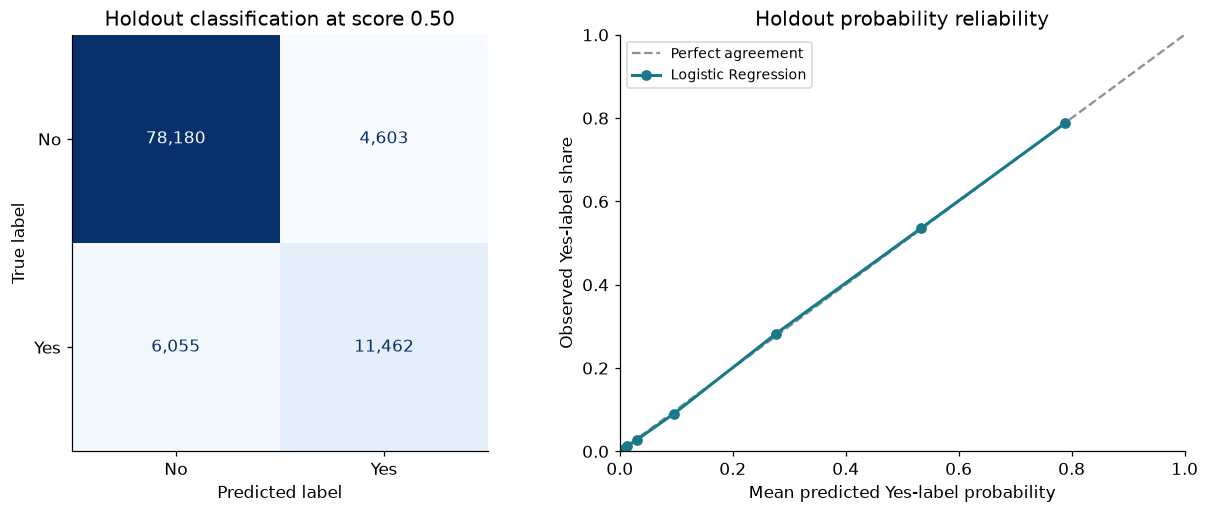

In [11]:
y_holdout = holdout_predictions["y_true"].to_numpy()
p_holdout = holdout_predictions["yes_probability"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.8))
confusion = confusion_matrix(y_holdout, (p_holdout >= 0.5).astype(int), labels=[0, 1])
ConfusionMatrixDisplay(confusion, display_labels=["No", "Yes"]).plot(ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title("Holdout classification at score 0.50")
fraction_yes, mean_probability = calibration_curve(y_holdout, p_holdout, n_bins=10, strategy="quantile")
axes[1].plot([0, 1], [0, 1], color="#87949A", linestyle="--", label="Perfect agreement")
axes[1].plot(mean_probability, fraction_yes, marker="o", linewidth=2, color="#187A89", label=selected_model)
axes[1].set(xlabel="Mean predicted Yes-label probability", ylabel="Observed Yes-label share", title="Holdout probability reliability", xlim=(0, 1), ylim=(0, 1))
axes[1].legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "holdout_confusion_and_calibration.png", bbox_inches="tight")
plt.show()

### 8. Save the exact evaluated pipeline and reproducibility records

Saving a fitted pipeline preserves the same encoding, scaling, feature
ordering, and classifier used in the holdout evaluation. The application
loads this pipeline; it does not train a new model during an upload.

Artifacts include the model bundle, metadata, split
membership, validation and holdout tables, charts, and a small unlabeled
demonstration CSV from Kaggle `test.csv`. Only load trusted project model
files: Python pickle/joblib files are not safe to load from arbitrary uploads.

In [12]:
metadata = save_training_artifacts(
    ROOT, splits, candidates,
    validation_metrics, validation_ranking, validation_predictions,
    selected_model, final_pipeline,
    holdout_metrics, holdout_ranking, holdout_predictions,
)
artifact_paths = [
    "models/model_bundle.joblib",
    "models/model_metadata.json",
    "data/splits/split_membership.csv",
    "docs/reports/modeling/validation_metrics.csv",
    "docs/reports/modeling/validation_ranking.csv",
    "docs/reports/modeling/holdout_metrics.csv",
    "docs/reports/modeling/holdout_ranking.csv",
    "data/demo/customer_profiles_demo.csv",
]
show_table(pd.DataFrame({"Artifact": artifact_paths, "Exists": [(ROOT / path).is_file() for path in artifact_paths]}))
print("Saved model:", metadata["selected_model"])
print("Training timestamp (UTC):", metadata["trained_at_utc"])
print("Seed:", metadata["seed"])
print("Model input count:", len(metadata["feature_columns"]))

Saved model bundle, metadata, split membership, evaluation tables, and demo CSV under /Users/nguyenchau/Documents/msba265/Predicting Electric Vehicle Purchases.


,Artifact,Exists
0,models/model_bundle.joblib,True
1,models/model_metadata.json,True
2,data/splits/split_membership.csv,True
3,docs/reports/modeling/validation_metrics.csv,True
4,docs/reports/modeling/validation_ranking.csv,True
5,docs/reports/modeling/holdout_metrics.csv,True
6,docs/reports/modeling/holdout_ranking.csv,True
7,data/demo/customer_profiles_demo.csv,True


Saved model: Logistic Regression
Training timestamp (UTC): 2026-10-11T00:25:46.604045+00:00
Seed: 42
Model input count: 13


### 8.1 Measured training evidence

The evidence keeps two fits distinct. For the checked-in artifacts inspected on October 27, 2026:

- **Saved application model:** fitted earlier on training plus validation (85%). Its stored estimator records 47 iterations. Original timing and warning observations were not saved, so those values remain unknown.
- **Fresh diagnostic fit:** repeats only the 70% training fit with the same settings and training-fitted preprocessing. A native scikit-learn callback measures training and validation log loss after each completed L-BFGS iteration. It does not use holdout data or validation-based stopping, and it does not replace the application model.

That checked-in diagnostic has 48 iterations. A future Run All records new fits
and their available timing/warning observations in the table below. The original
47/48 counts are observations for this revision, not required iteration counts. Runtime includes monitoring and is
machine dependent. When reproducing the notebook, the guard below reuses matching
evidence or generates a new trace if the model, inputs, source, or outputs changed.


In [2]:
import hashlib
import json
from ev_project.training_diagnostics import run_training_diagnostics

def evidence_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def matching_training_evidence(report):
    try:
        provenance = report["provenance"]
        required = {
            "model_bundle.joblib": ROOT / "models/model_bundle.joblib",
            "model_metadata.json": ROOT / "models/model_metadata.json",
        }
        for name, path in required.items():
            if evidence_sha256(path) != provenance["application_artifact_sha256"][name]:
                return False
        for name, relative in [("train.csv", "train.csv"),
                               ("train_clean.csv", "data/processed/train_clean.csv")]:
            if evidence_sha256(ROOT / relative) != provenance["source_sha256"][name]:
                return False
        if evidence_sha256(ROOT / "data/splits/split_membership.csv") != provenance["split_membership_sha256"]:
            return False
        for name in ["modeling.py", "training_diagnostics.py"]:
            if evidence_sha256(ROOT / "ev_project" / name) != provenance["source_code_sha256"][name]:
                return False
        for name, expected in provenance["output_sha256"].items():
            if evidence_sha256(ROOT / "docs/reports/modeling" / name) != expected:
                return False
        return isinstance(report["loss_history"], dict)
    except (KeyError, TypeError, FileNotFoundError):
        return False

report_path = ROOT / "docs/reports/modeling/training_diagnostics.json"
try:
    training_evidence = json.loads(report_path.read_text()) if report_path.exists() else None
except (json.JSONDecodeError, UnicodeDecodeError, FileNotFoundError):
    training_evidence = None
if training_evidence is None or not matching_training_evidence(training_evidence):
    training_evidence = run_training_diagnostics(ROOT)

fit_table = pd.DataFrame(training_evidence["fit_records"])[[
    "fit_role", "fit_rows", "solver", "actual_iterations", "max_iter", "tol",
    "elapsed_seconds", "convergence_warning_observed", "fit_status",
]]
display(fit_table)
display(Markdown(
    "**Interpretation:** the application fit and the separately measured training-only fit "
    "have different roles. Missing historical measurements are not zero. "
    "The exact optimizer stopping criterion is not exposed; validation loss is observation only."
))


,fit_role,fit_rows,solver,actual_iterations,max_iter,tol,elapsed_seconds,convergence_warning_observed,fit_status
0,saved_application_model,568365,lbfgs,47,1000,0.0001,NaN,None,saved_artifact_snapshot
1,fresh_train_only_diagnostic,468065,lbfgs,48,1000,0.0001,2.700248,False,success


**Interpretation:** the application fit and the separately measured training-only fit have different roles. Missing historical measurements are not zero. The exact optimizer stopping criterion is not exposed; validation loss is observation only.

,iteration,training_log_loss,validation_log_loss,elapsed_seconds
43,44,0.232579,0.232748,2.527609
44,45,0.232566,0.232757,2.569823
45,46,0.232559,0.232750,2.612015
46,47,0.232555,0.232738,2.654180
47,48,0.232554,0.232742,2.698772


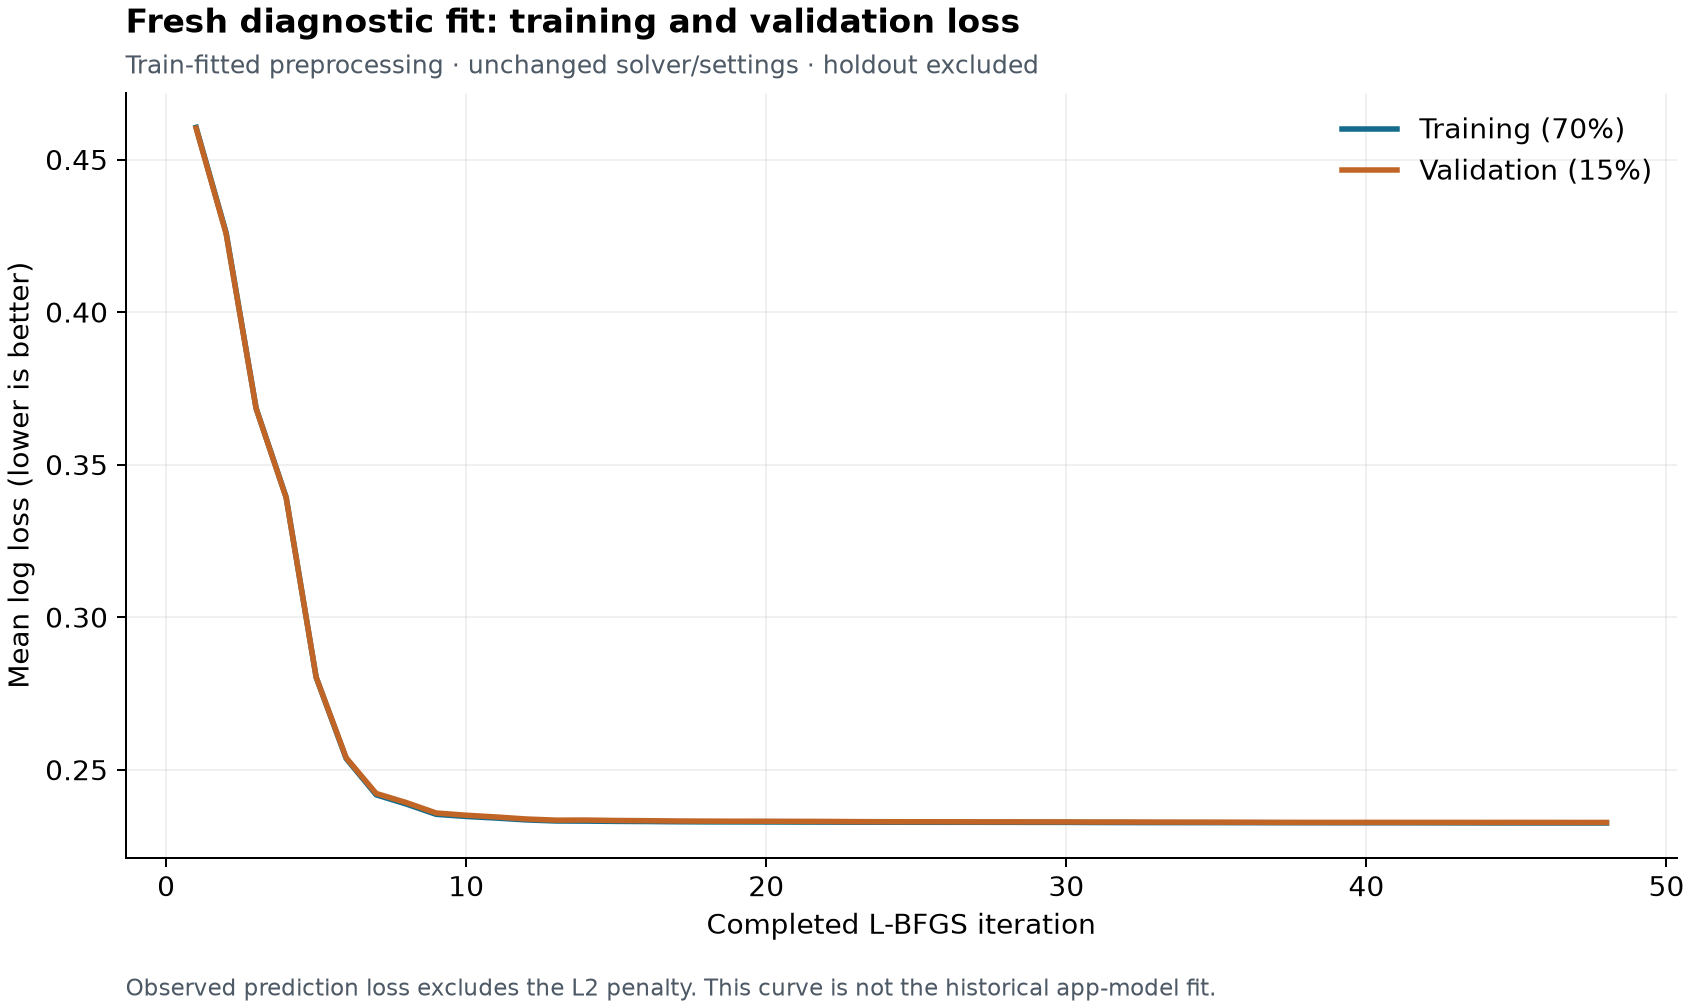

**Interpretation:** mean training log loss changes from 0.460562 to 0.232554; validation log loss ends at 0.232742. The curves drop quickly and level off, with similar recorded training and validation loss. This supports a stable optimization run on this internal split, while leaving external performance, calibration, and demographic-group reliability unestablished. The graph excludes the L2 penalty and is not the original 85%-fit model's loss history.

In [3]:
from IPython.display import Image

loss_history = pd.read_csv(ROOT / "docs/reports/modeling/lbfgs_loss_history.csv")
assert len(loss_history) == training_evidence["loss_history"]["rows"]
assert loss_history["iteration"].tolist() == list(range(1, len(loss_history) + 1))
display(loss_history.tail())
display(Image(filename=str(ROOT / "docs/reports/modeling/figures/lbfgs_loss_history.png")))
last = loss_history.iloc[-1]
display(Markdown(
    f"**Interpretation:** mean training log loss changes from "
    f"{loss_history.iloc[0].training_log_loss:.6f} to {last.training_log_loss:.6f}; "
    f"validation log loss ends at {last.validation_log_loss:.6f}. "
    "The curves drop quickly and level off, with similar recorded training and validation loss. "
    "This supports a stable optimization run on this internal split, while leaving external "
    "performance, calibration, and demographic-group reliability unestablished. "
    "The graph excludes the L2 penalty and is not the original 85%-fit model's loss history."
))


### 8.2 Reproduce or inspect the diagnostic independently

From the project root, use the same environment as the main notebook:

~~~bash
python -m ev_project.training_diagnostics
~~~

The command writes training_diagnostics.json, training_diagnostics.csv,
lbfgs_loss_history.csv, and the loss figure under docs/reports/modeling/.
It verifies the saved model, source data, and split provenance, and confirms the
application model and metadata remain byte-identical. The current saved-model
reload evidence is in docs/reports/modeling/saved_model_score_reload_evidence.json.

A normal future modeling run also records its three candidate fits and the final
fit in metadata and fit_summary.json/csv. Those summaries are separate from the
native callback trace, so saving a model does not silently overwrite loss evidence.
The existing main reproduction commands and Kaggle API access remain unchanged.

The current P2 draft paper and stakeholder slides are in docs/P2/. The paper
contains the technical method and evidence; the slides explain the dealership
problem, product use, findings, and limitations in business language.


### 9. How the Streamlit app uses this work

1. Upload an unlabeled CSV containing `id` and the 13 input fields. The
   supplied demo is a safe starting point; its rows have no target labels.
2. The app checks the input schema, required values, category membership,
   numeric domains, and identifiers before scoring.
3. Choose the number of customers **K** that can be contacted.
4. The saved pipeline computes Yes-label scores. The app sorts scores from
   highest to lowest and uses the same reproducible ID tie rule.
5. Review the top K and download the ranked results for a proposed outreach
   list. Actual outcomes would need to be collected before measuring real
   customer performance.

The app is a class-project decision-support prototype. It does not contact
customers automatically, verify their purchase intent, or make eligibility
decisions. Real deployment would require a lawful and appropriate data
collection process, subgroup review, and validation on real labeled profiles.

**Monitoring plan:** check invalid inputs and scoring failures, observe
changes in feature and score distributions, and reevaluate ranking and
calibration when reliable new outcome labels become available. With this
static synthetic dataset, live drift and business impact remain unmeasured.

### 10. Conclusions and limits to carry into the presentation

- The validation comparison selects a candidate under a fixed contact-capacity
  assumption. Holdout results assess its final refit under that same rule.
- Lift@K summarizes enrichment of supplied Yes labels. It is not a causal
  uplift estimate, additional sales count, or return-on-investment calculation.
- No missing-value repair or outlier removal was needed in the initial audit;
  real customer uploads may have defects and should not be silently repaired.
- Gender and other demographic fields are present. Predictive usefulness
  does not by itself justify operational use. Review subgroup outcomes and
  whether each field belongs in the intended outreach process before a real
  deployment. No fairness conclusion has been established here.
- One fixed split, three modest candidates, and synthetic data limit the
  strength of conclusions. Future work can use cross-validation, external
  labeled data, and a confirmed outreach capacity without repeatedly tuning
  against the holdout used here.

**References:** [Kaggle competition](https://www.kaggle.com/competitions/playground-series-s6e9),
[scikit-learn Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html),
[model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html),
[probability calibration](https://scikit-learn.org/stable/modules/calibration.html),
[Streamlit documentation](https://docs.streamlit.io/).